In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "stockwise.db").exists():
    ROOT = ROOT.parent

con = sqlite3.connect(ROOT / "stockwise.db")
sales = pd.read_sql_query("SELECT * FROM sales_enriched", con, parse_dates=["sale_date"])
products = pd.read_sql_query("SELECT * FROM products", con)
inventory = pd.read_sql_query("SELECT * FROM inventory", con)
print(sales.shape)
sales.head()

(346107, 19)


,line_id,invoice_id,sale_date,store_id,product_id,qty,selling_price,discount_pct,payment_mode,category,sku_name,gst_rate,city,region,gross_sales,net_revenue,cogs,gross_profit,fy
0,1,INV-ST01-20240401-001,2024-04-01,ST01,P007,1,99.75,5.0,UPI,Staples & Grains,Masoor Dal 1 kg,5,Pune,West,99.75,95.000000,86.27,8.730000,2024-25
1,2,INV-ST01-20240401-001,2024-04-01,ST01,P042,3,13.30,5.0,UPI,Snacks,Instant Noodles Masala 70 g,5,Pune,West,39.90,38.000000,29.10,8.900000,2024-25
2,3,INV-ST01-20240401-001,2024-04-01,ST01,P056,2,130.00,0.0,UPI,Beverages,Green Tea Bags 25 pcs,5,Pune,West,260.00,247.619048,202.42,45.199048,2024-25
3,4,INV-ST01-20240401-001,2024-04-01,ST01,P067,2,171.00,5.0,UPI,Personal Care,Face Wash 100 ml,18,Pune,West,342.00,289.830508,230.84,58.990508,2024-25
4,5,INV-ST01-20240401-002,2024-04-01,ST01,P021,3,90.00,0.0,UPI,Dairy,Paneer 200 g,5,Pune,West,270.00,257.142857,218.31,38.832857,2024-25


In [2]:
print("Missing values:\n", sales.isna().sum()[lambda s: s > 0], "\n")
print("Duplicate rows:", sales.drop(columns="line_id").duplicated().sum())
print("qty <= 0:", (sales["qty"] <= 0).sum())
print("price above MRP:", (sales["selling_price"] > sales["gst_rate"].map(lambda g: np.inf)).sum(), "(see MRP check below)")

chk = sales.merge(products[["product_id", "mrp", "unit_cost"]], on="product_id")
print("selling_price > MRP:", (chk["selling_price"] > chk["mrp"]).sum())
print("sold below cost (ex-GST):", (chk["net_revenue"] < chk["cogs"]).sum())
print("\nData types:\n", sales.dtypes)
sales[["qty", "selling_price", "discount_pct", "net_revenue"]].describe().round(2)

Missing values:
 Series([], dtype: int64) 

Duplicate rows: 0
qty <= 0: 0
price above MRP: 0 (see MRP check below)
selling_price > MRP: 0
sold below cost (ex-GST): 0

Data types:
 line_id                   int64
invoice_id                  str
sale_date        datetime64[us]
store_id                    str
product_id                  str
qty                       int64
selling_price           float64
discount_pct            float64
payment_mode                str
category                    str
sku_name                    str
gst_rate                  int64
city                        str
region                      str
gross_sales             float64
net_revenue             float64
cogs                    float64
gross_profit            float64
fy                          str
dtype: object


,qty,selling_price,discount_pct,net_revenue
count,346107.00,346107.00,346107.00,346107.00
mean,2.93,108.98,0.83,220.50
std,3.10,103.26,2.36,243.01
min,1.00,12.60,0.00,12.00
25%,1.00,40.50,0.00,84.75
50%,2.00,85.00,0.00,148.57
75%,4.00,130.00,0.00,261.90
max,67.00,650.00,10.00,4452.38


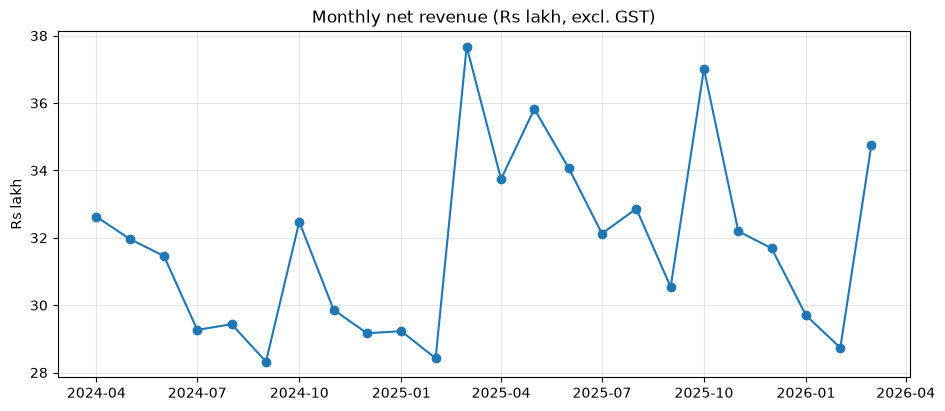

In [4]:
(ROOT / "images").mkdir(exist_ok=True)

monthly = sales.set_index("sale_date")["net_revenue"].resample("MS").sum() / 1e5

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Monthly net revenue (Rs lakh, excl. GST)")
ax.set_ylabel("Rs lakh")
ax.grid(alpha=0.3)
fig.savefig(ROOT / "images" / "01_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

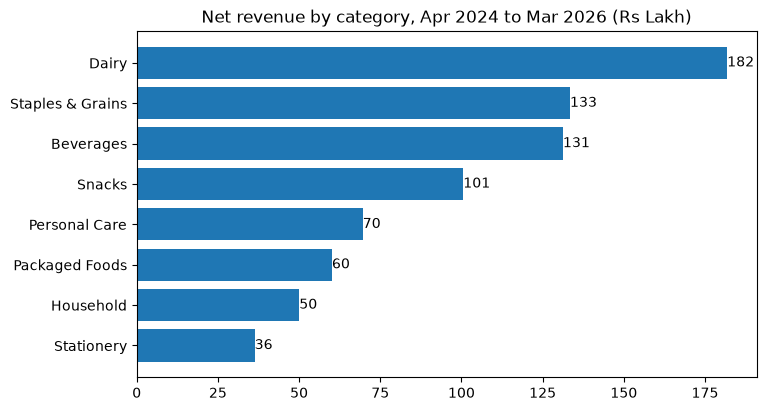

In [5]:
cat = sales.groupby("category")["net_revenue"].sum().sort_values() / 1e5

fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(cat.index, cat.values)
ax.set_title("Net revenue by category, Apr 2024 to Mar 2026 (Rs Lakh)")
for y, v in enumerate(cat.values):
    ax.text(v, y, f"{v:,.0f}", va="center")
fig.savefig(ROOT / "images"/ "02_categor_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_19128\2498580221.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wd = daily.groupby(daily.index.dayofweek).mean() / 1e3


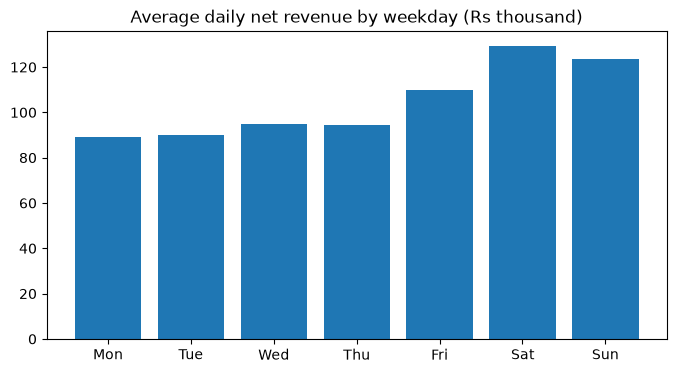

Mon    1.00
Tue    1.01
Wed    1.06
Thu    1.06
Fri    1.23
Sat    1.45
Sun    1.38
Name: net_revenue, dtype: float64


In [6]:
daily = sales.groupby("sale_date")["net_revenue"].sum()
wd = daily.groupby(daily.index.dayofweek).mean() / 1e3
wd.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(wd.index, wd.values)
ax.set_title("Average daily net revenue by weekday (Rs thousand)")
fig.savefig(ROOT / "images" / "03_weekday_pattern.png", dpi=150, bbox_inches="tight")
plt.show()
print((wd / wd["Mon"]).round(2))

payment_mode
UPI     55.0
Card    24.9
Cash    20.0
Name: proportion, dtype: float64


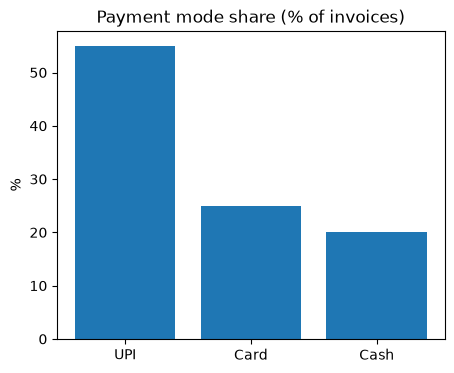

In [7]:
pay = sales.drop_duplicates("invoice_id")["payment_mode"].value_counts(normalize=True) * 100
print(pay.round(1))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(pay.index, pay.values)
ax.set_title("Payment mode share (% of invoices)")
ax.set_ylabel("%")
fig.savefig(ROOT / "images" / "04_payment_mode.png", dpi=150, bbox_inches="tight")
plt.show()